# Document Recognition

Synthetic ID cards with automatic field labels, YOLO field detection and OCR.
Code lives in `src/`, this notebook shows the results.

In [1]:
%load_ext autoreload
%autoreload 2

import random 
from pathlib import Path 

from PIL import Image, ImageDraw

from src.fake_person import random_person
from src.render_card import render_card

In [2]:
from src.render_card import TEMPLATES  
from src.augment import augment  

In [3]:
rng = random.Random(42)
person = random_person(rng)
person                     

{'surname': 'Иванова',
 'name': 'Виктория',
 'patronymic': 'Юрьевна',
 'birth_date': '04.09.1974',
 'number': 'ГС 2458591'}

photo (40, 120, 260, 400) None
surname (300, 140, 438, 163) Иванова
name (300, 215, 454, 244) Виктория
patronymic (300, 290, 448, 319) Юрьевна
birth_date (300, 365, 462, 388) 04.09.1974
number (300, 440, 476, 463) ГС 2458591


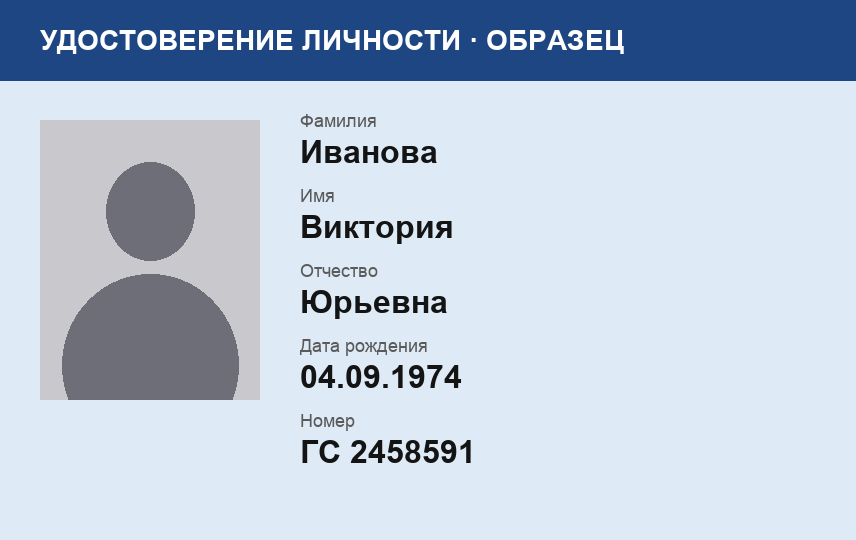

In [4]:
card, fields = render_card(person)

for f in fields: 
    print(f["cls"], f["box"], f["text"])

card

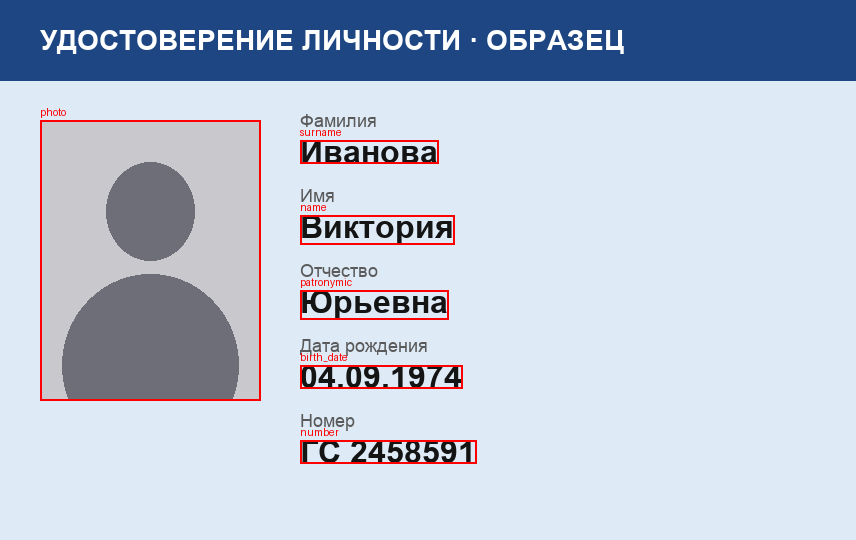

In [5]:
def draw_boxes(card, fields):                
    card = card.copy()                        
    draw = ImageDraw.Draw(card)               
    for f in fields:          
        draw.rectangle(f["box"], outline="red", width=2)
        draw.text((f["box"][0], f["box"][1] - 14), f["cls"], fill="red")
    return card          

draw_boxes(card, fields)              

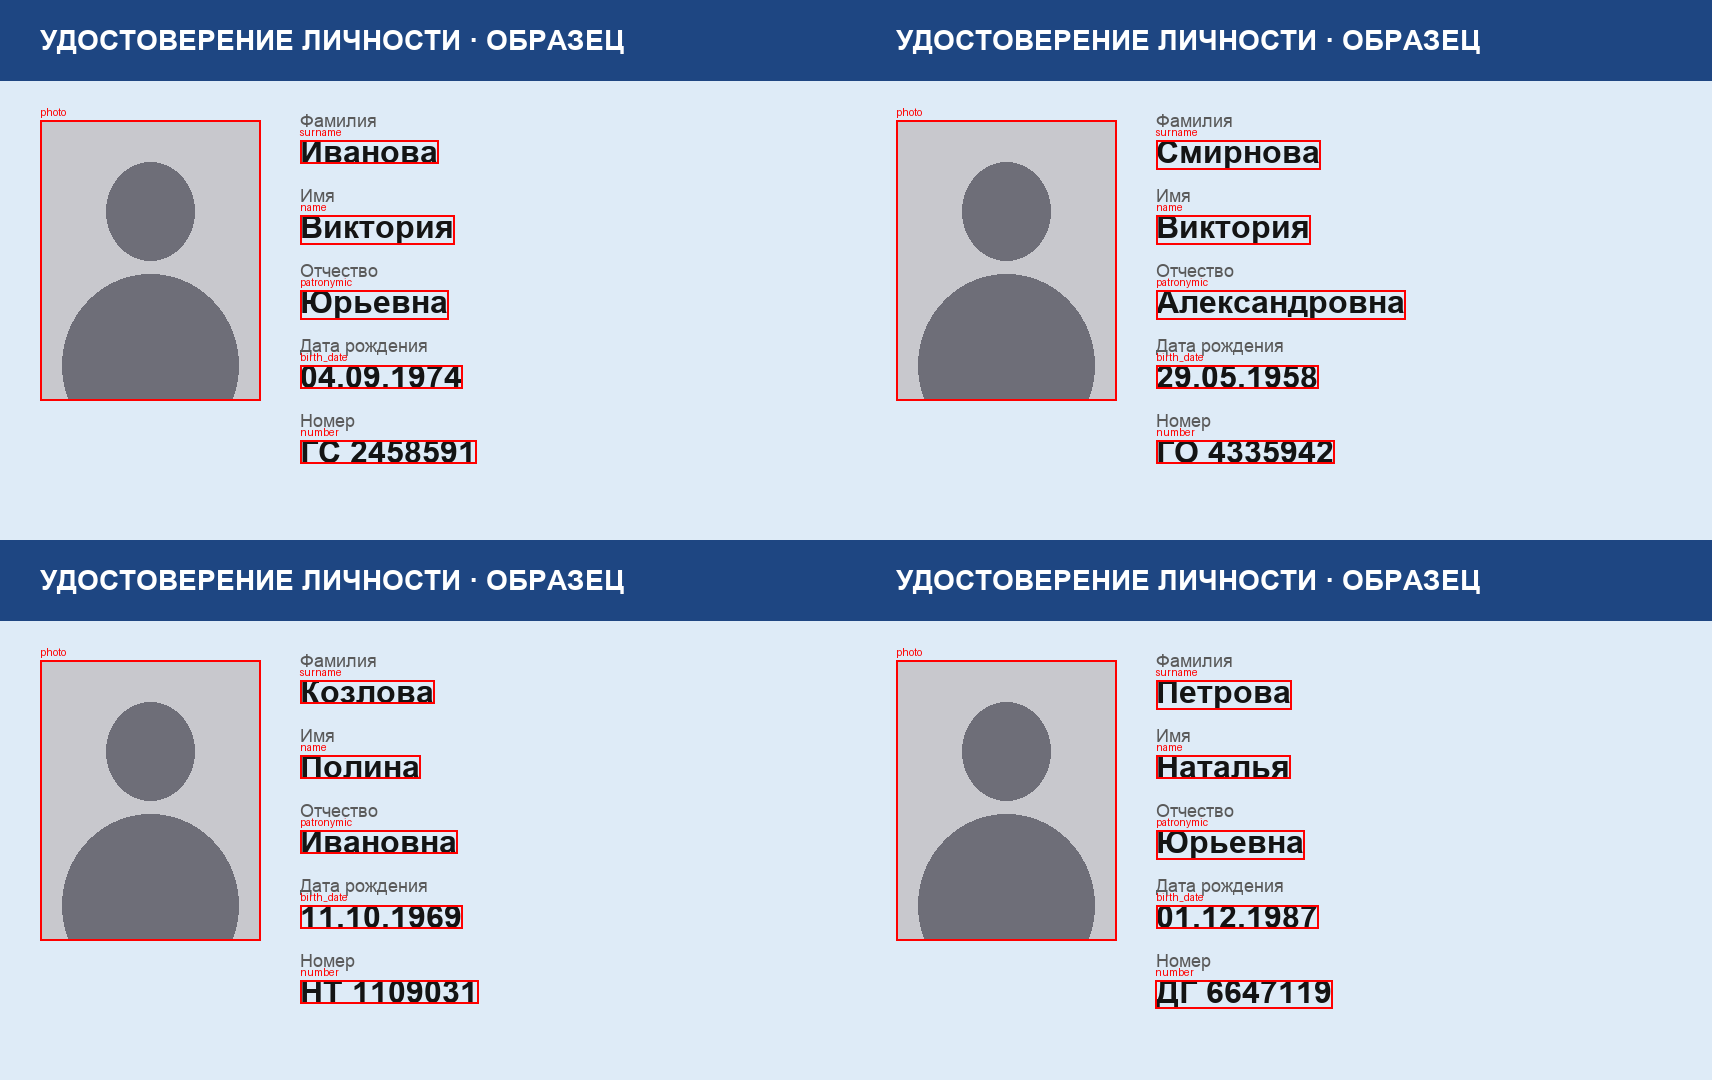

In [6]:
rng = random.Random(42)            
cards = []                   
for _ in range(4):                
    card, fields = render_card(random_person(rng))
    cards.append(draw_boxes(card, fields))

w, h = cards[0].size        
grid = Image.new("RGB", (2 * w, 2 * h), "white")

for i, c in enumerate(cards):
    grid.paste(c, ((i % 2) * w, (i // 2) * h))

out = Path("docs/images/card_preview.png")
out.parent.mkdir(parents=True, exist_ok=True)
grid.save(out)                       
grid                                      

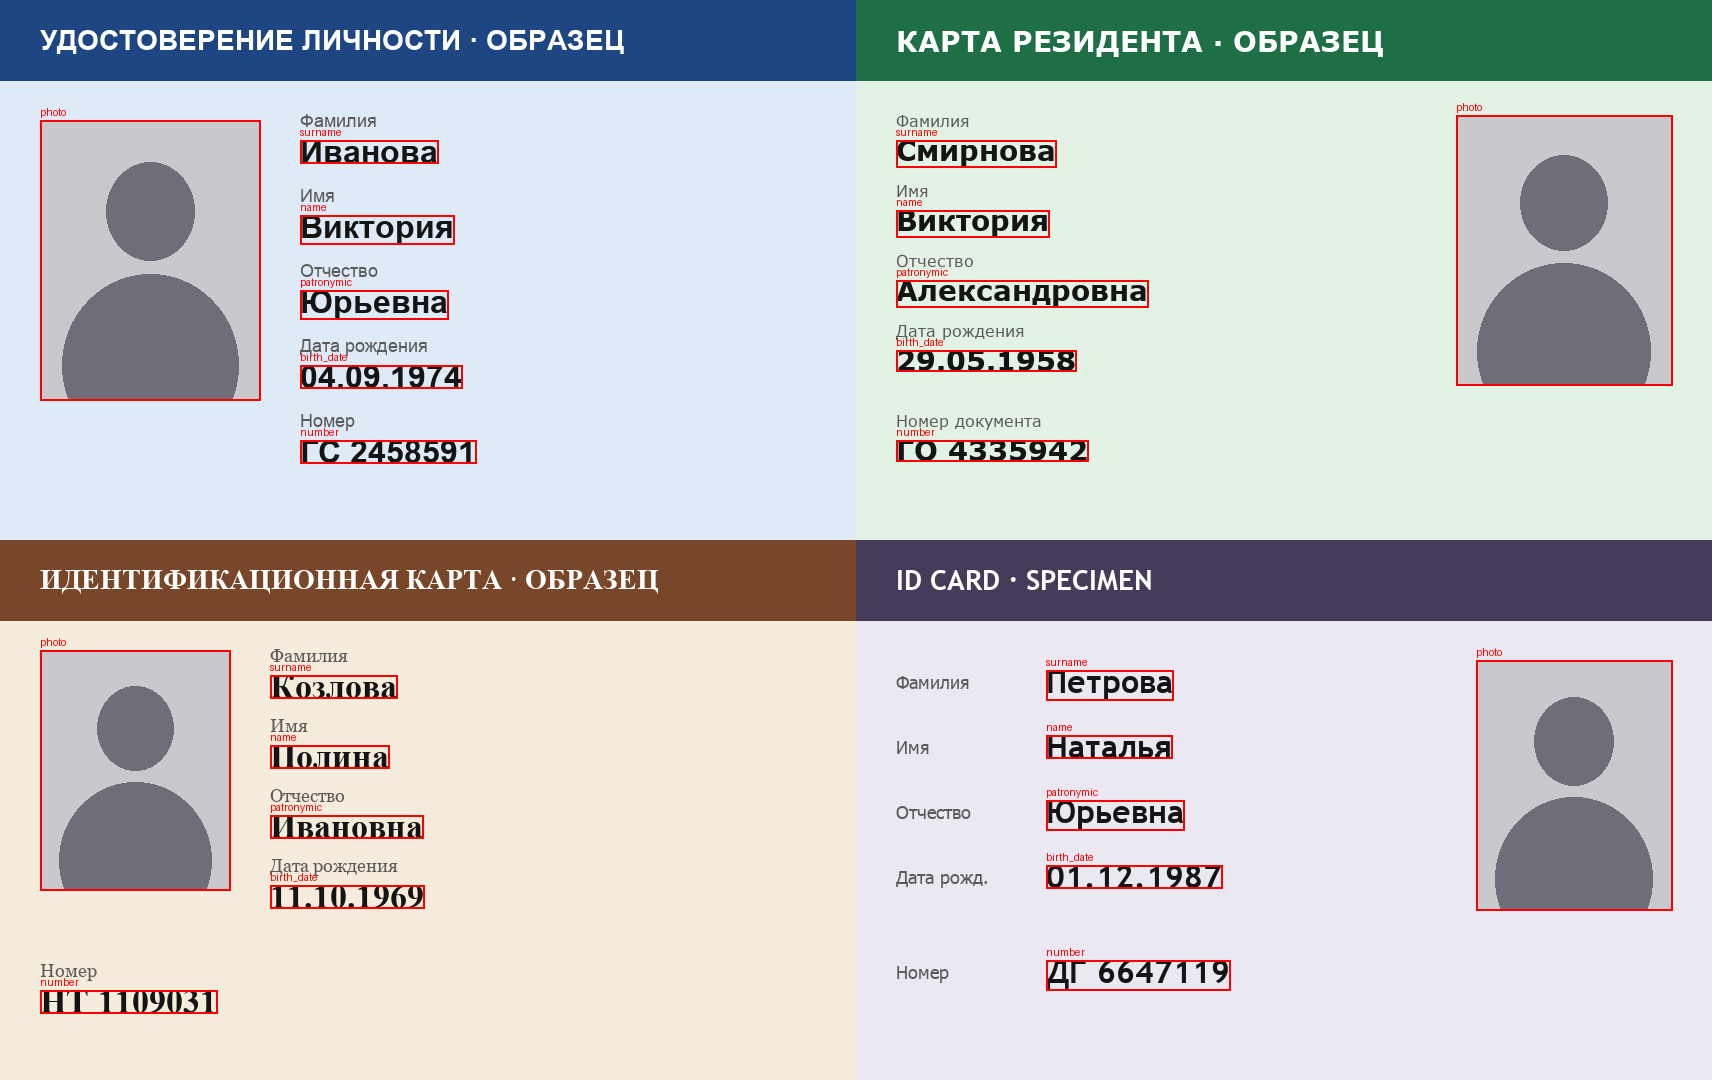

In [7]:
from src.render_card import TEMPLATES     
from src.augment import augment         

def make_grid(images, cols=2):                       
    w, h = images[0].size                           
    rows = (len(images) + cols - 1) // cols         
    grid = Image.new("RGB", (cols * w, rows * h), "white")   
    for i, im in enumerate(images):                 
        grid.paste(im, ((i % cols) * w, (i // cols) * h))    
    return grid

rng = random.Random(42)                             
flat = []                                          
for t in TEMPLATES:                       
    card, fields = render_card(random_person(rng), t)   
    flat.append(draw_boxes(card, fields))          

templates_grid = make_grid(flat)               
templates_grid.save("docs/images/templates.png")   
templates_grid                                 

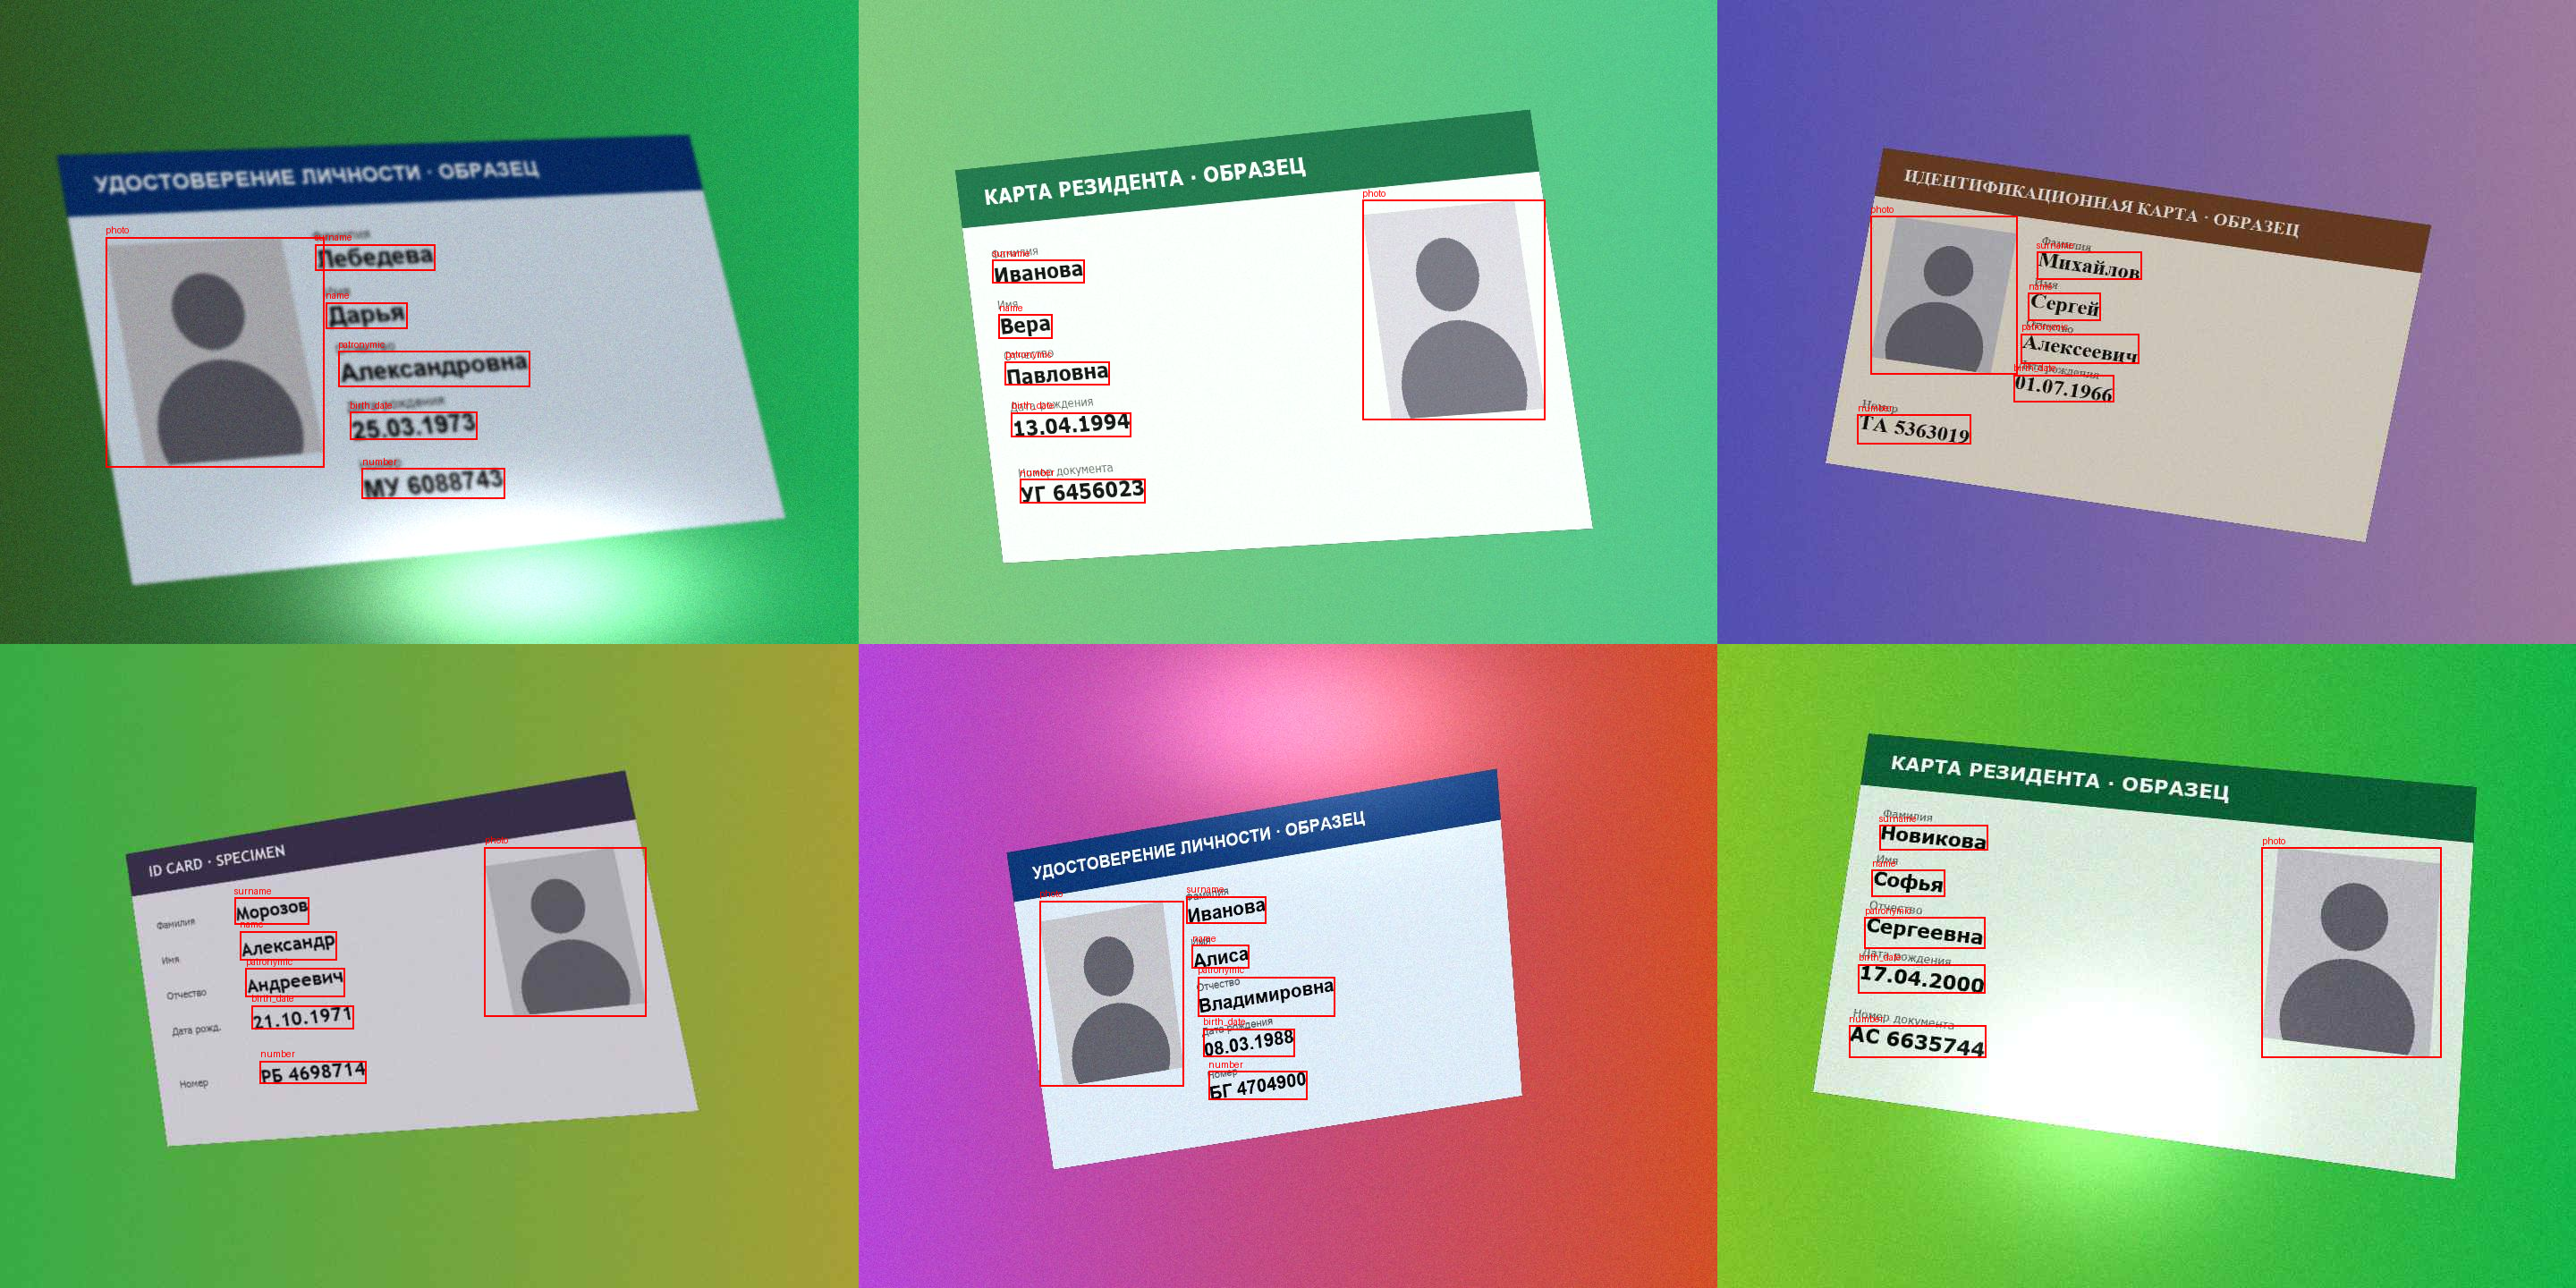

In [8]:
rng = random.Random(0)                               
photos = []                                         
for i in range(6):                                
    t = TEMPLATES[i % 4]                         
    card, fields = render_card(random_person(rng), t)    
    photo, fields = augment(card, fields, rng)      
    photos.append(draw_boxes(photo, fields))    

augmented_grid = make_grid(photos, cols=3)        
augmented_grid.save("docs/images/augmented.png")     
augmented_grid                             